# Unsupervised Learning & Feature Reduction on UCI HAR

Dataset: *Human Activity Recognition Using Smartphones* (UCI) — 561 engineered features computed from
2.56 s windows of smartphone accelerometer/gyroscope signals, 30 subjects, 6 activities.

**Protocol.** The provided training set is split by subject into **train** and **dev**; all exploration,
reduction and model selection use only these. The provided **test** set is loaded and scaled in Phase 1
(with the scaler fitted on train only) and cached, but it is not analysed, plotted or scored until the
single final evaluation in Phase 5. Activity labels are never given to the unsupervised methods — they are
only used afterwards to evaluate them.

All figures are saved to `figures/` (PNG, dpi=200), all numeric results to `results/` (CSV), and the
processed arrays to `cache/`.

## Phase 1 - Setup

The cells below import the libraries, fix `random_state=42`, and define the shared helpers (locating and
loading the dataset, saving figures/tables, the subject-wise split, the cache). They then load the provided
train and test sets, split the provided training set into train/dev **by subject**, fit a `StandardScaler`
on train only, transform train/dev/test with it, and cache the processed arrays to `cache/har_processed.npz`
so later phases load them quickly.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_DIR = Path.cwd()
FIG_DIR = PROJECT_DIR / "figures"
RES_DIR = PROJECT_DIR / "results"
CACHE_DIR = PROJECT_DIR / "cache"
CACHE_FILE = CACHE_DIR / "har_processed.npz"
for d in (FIG_DIR, RES_DIR, CACHE_DIR):
    d.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

In [2]:
# ---------- Shared helpers: locating and loading the dataset ----------

def find_data_dir(root=PROJECT_DIR):
    """Find the extracted 'UCI HAR Dataset' directory (has train/, test/, features.txt, activity_labels.txt).

    Searches the project folder; ignores macOS '__MACOSX' metadata copies. Nothing is downloaded or extracted.
    """
    for features_file in sorted(root.rglob("features.txt")):
        d = features_file.parent
        if "__MACOSX" in d.parts:
            continue
        if (d / "activity_labels.txt").exists() and (d / "train").is_dir() and (d / "test").is_dir():
            return d
    raise FileNotFoundError(f"No 'UCI HAR Dataset' directory found under {root}")


DATA_DIR = find_data_dir()
print("Dataset directory:", DATA_DIR.relative_to(PROJECT_DIR))


def load_activity_labels():
    """Map integer activity code -> activity name."""
    df = pd.read_csv(DATA_DIR / "activity_labels.txt", sep=r"\s+", header=None, names=["code", "activity"])
    return dict(zip(df["code"], df["activity"]))


def load_feature_names():
    """Return the 561 feature names, made unique (features.txt repeats some band-energy names)."""
    names = pd.read_csv(DATA_DIR / "features.txt", sep=r"\s+", header=None, names=["idx", "name"])["name"]
    counts, unique = {}, []
    for n in names:
        counts[n] = counts.get(n, 0) + 1
        unique.append(n if counts[n] == 1 else f"{n}_{counts[n]}")
    return unique


ACTIVITY_LABELS = load_activity_labels()
ACTIVITY_ORDER = [ACTIVITY_LABELS[k] for k in sorted(ACTIVITY_LABELS)]
FEATURE_NAMES = load_feature_names()


def load_split(split):
    """Load one provided split ('train' or 'test').

    Returns X (DataFrame, 561 named features), y (Series of activity NAMES), subject (int Series).
    """
    assert split in ("train", "test")
    d = DATA_DIR / split
    X = pd.read_csv(d / f"X_{split}.txt", sep=r"\s+", header=None, names=FEATURE_NAMES)
    codes = pd.read_csv(d / f"y_{split}.txt", header=None)[0]
    y = pd.Series(pd.Categorical(codes.map(ACTIVITY_LABELS), categories=ACTIVITY_ORDER), name="activity")
    subject = pd.read_csv(d / f"subject_{split}.txt", header=None)[0].rename("subject")
    return X, y, subject


# ---------- Shared helpers: saving outputs ----------

def save_fig(fig, name):
    """Save a figure to figures/<name>.png at dpi=200 (it is also shown inline)."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"saved {path.relative_to(PROJECT_DIR)}")


def save_table(df, name, index=True):
    """Save a table to results/<name>.csv."""
    path = RES_DIR / f"{name}.csv"
    df.to_csv(path, index=index)
    print(f"saved {path.relative_to(PROJECT_DIR)}")


TIMINGS = []

def record_timing(phase, step, seconds):
    """Log a wall-clock timing to results/timings.csv. Timings vary run to run, so they live in this one
    file instead of the per-phase result tables (which then stay identical across re-runs)."""
    TIMINGS.append({"phase": phase, "step": step, "seconds": round(seconds, 3)})
    pd.DataFrame(TIMINGS).to_csv(RES_DIR / "timings.csv", index=False)


# ---------- Shared helpers: splitting ----------

def subject_split(X, y, subject, dev_size=0.2):
    """Split by SUBJECT with GroupShuffleSplit (~dev_size of subjects to dev) so no person is in both."""
    gss = GroupShuffleSplit(n_splits=1, test_size=dev_size, random_state=RANDOM_STATE)
    tr_idx, dev_idx = next(gss.split(X, y, groups=subject))
    take = lambda obj, idx: obj.iloc[idx].reset_index(drop=True)
    return (take(X, tr_idx), take(y, tr_idx), take(subject, tr_idx),
            take(X, dev_idx), take(y, dev_idx), take(subject, dev_idx))


# ---------- Shared helpers: processed-data cache ----------

def load_cache(path=CACHE_FILE):
    """Load the processed arrays written in Phase 1.

    Returns a dict with X_{train,dev,test} (standardized float arrays), y_{train,dev,test} (activity names),
    subject_{train,dev,test}, feature_names, activity_order, scaler_mean, scaler_scale.
    """
    with np.load(path, allow_pickle=False) as z:
        return {k: z[k] for k in z.files}

Dataset directory: human+activity+recognition+using+smartphones\UCI HAR Dataset\UCI HAR Dataset


In [3]:
# Load the provided train and test sets
t0 = time.perf_counter()
X_train_full, y_train_full, subject_train_full = load_split("train")
X_test, y_test, subject_test = load_split("test")
print(f"Loaded in {time.perf_counter() - t0:.1f}s")
print(f"Provided train: X={X_train_full.shape}, {subject_train_full.nunique()} subjects, "
      f"{X_train_full.isna().sum().sum()} missing values")
print(f"Provided test:  X={X_test.shape}, {subject_test.nunique()} subjects, "
      f"{X_test.isna().sum().sum()} missing values")
print(f"Features: {len(FEATURE_NAMES)} ({len(set(FEATURE_NAMES))} unique after de-duplication); "
      f"activities: {ACTIVITY_ORDER}")
X_train_full.iloc[:5, :8]

Loaded in 1.9s
Provided train: X=(7352, 561), 21 subjects, 0 missing values
Provided test:  X=(2947, 561), 9 subjects, 0 missing values
Features: 561 (561 unique after de-duplication); activities: ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672


In [4]:
# Split the provided training set into train / dev BY SUBJECT
X_train, y_train, subject_train, X_dev, y_dev, subject_dev = subject_split(
    X_train_full, y_train_full, subject_train_full, dev_size=0.2)

assert set(subject_train).isdisjoint(subject_dev), "subject leakage between train and dev"
assert set(subject_train_full).isdisjoint(subject_test), "provided train/test share subjects"

for name, s in [("train", subject_train), ("dev", subject_dev), ("test", subject_test)]:
    print(f"{name:5s}: {len(s):5d} rows, {s.nunique():2d} subjects -> {sorted(s.unique().tolist())}")

split_summary = pd.DataFrame({
    "train": y_train.value_counts().reindex(ACTIVITY_ORDER),
    "dev": y_dev.value_counts().reindex(ACTIVITY_ORDER),
    "test": y_test.value_counts().reindex(ACTIVITY_ORDER),
})
split_summary.index.name = "activity"
split_summary.loc["TOTAL"] = split_summary.sum()
for c in ["train", "dev", "test"]:
    split_summary[f"{c}_%"] = (100 * split_summary[c] / split_summary.loc["TOTAL", c]).round(1)
split_summary.loc["n_subjects", ["train", "dev", "test"]] = [
    subject_train.nunique(), subject_dev.nunique(), subject_test.nunique()]
split_summary[["train", "dev", "test"]] = split_summary[["train", "dev", "test"]].astype(int)

save_table(split_summary, "phase1_split_summary")
display(split_summary)

train:  5551 rows, 16 subjects -> [5, 6, 7, 8, 11, 14, 16, 17, 19, 21, 22, 23, 26, 28, 29, 30]
dev  :  1801 rows,  5 subjects -> [1, 3, 15, 25, 27]
test :  2947 rows,  9 subjects -> [2, 4, 9, 10, 12, 13, 18, 20, 24]
saved results\phase1_split_summary.csv


,train,dev,test,train_%,dev_%,test_%
activity,,,,,,
WALKING,888,338,496,16.0,18.8,16.8
WALKING_UPSTAIRS,797,276,471,14.4,15.3,16.0
WALKING_DOWNSTAIRS,744,242,420,13.4,13.4,14.3
SITTING,993,293,491,17.9,16.3,16.7
STANDING,1053,321,532,19.0,17.8,18.1
LAYING,1076,331,537,19.4,18.4,18.2
TOTAL,5551,1801,2947,100.0,100.0,100.0
n_subjects,16,5,9,NaN,NaN,NaN


In [5]:
# Fit StandardScaler on TRAIN ONLY, then transform train, dev and test with it
scaler = StandardScaler().fit(X_train)
Xs_train = scaler.transform(X_train)
Xs_dev = scaler.transform(X_dev)
Xs_test = scaler.transform(X_test)

print(f"train after scaling: mean={Xs_train.mean():+.2e}, std={Xs_train.std():.3f}")
print(f"dev   after scaling: mean={Xs_dev.mean():+.3f}, std={Xs_dev.std():.3f}  (not exactly 0/1: scaler fit on train)")
print(f"Zero-variance features in train: {(scaler.scale_ == 0).sum()}")

train after scaling: mean=+4.06e-19, std=1.000
dev   after scaling: mean=-0.048, std=0.901  (not exactly 0/1: scaler fit on train)
Zero-variance features in train: 0


In [6]:
# Cache the processed arrays so later phases load them quickly
t0 = time.perf_counter()
np.savez_compressed(
    CACHE_FILE,
    X_train=Xs_train.astype(np.float32), X_dev=Xs_dev.astype(np.float32), X_test=Xs_test.astype(np.float32),
    y_train=y_train.to_numpy(dtype=str), y_dev=y_dev.to_numpy(dtype=str), y_test=y_test.to_numpy(dtype=str),
    subject_train=subject_train.to_numpy(), subject_dev=subject_dev.to_numpy(), subject_test=subject_test.to_numpy(),
    feature_names=np.array(FEATURE_NAMES), activity_order=np.array(ACTIVITY_ORDER),
    scaler_mean=scaler.mean_, scaler_scale=scaler.scale_,
)
print(f"Wrote {CACHE_FILE.relative_to(PROJECT_DIR)} ({CACHE_FILE.stat().st_size / 1e6:.1f} MB) "
      f"in {time.perf_counter() - t0:.1f}s")

# Round-trip check
t0 = time.perf_counter()
data = load_cache()
print(f"Reloaded in {time.perf_counter() - t0:.2f}s:",
      {k: v.shape for k, v in data.items() if k.startswith(("X_", "y_", "subject_"))})
assert np.allclose(data["X_train"], Xs_train, atol=1e-5) and (data["y_test"] == y_test.to_numpy(dtype=str)).all()

Wrote cache\har_processed.npz (19.7 MB) in 0.9s
Reloaded in 0.11s: {'X_train': (5551, 561), 'X_dev': (1801, 561), 'X_test': (2947, 561), 'y_train': (5551,), 'y_dev': (1801,), 'y_test': (2947,), 'subject_train': (5551,), 'subject_dev': (1801,), 'subject_test': (2947,)}


## Phase 2 - EDA

The cells below load the cached standardized arrays and use the **train split only**. They plot the activity
counts, fit PCA with all components on train, plot the explained variance ratio of the first 50 components and
the cumulative explained variance, locate the elbow programmatically (maximum distance to the line joining the
first and last points of the ratio curve over the first 50 components — the kneedle idea), report how many
components reach 90% and 95% cumulative variance, and show the train data on PC1 vs PC2 coloured by activity.

In [7]:
# Load the cached arrays from Phase 1 and keep the train split only
data = load_cache()
X_tr = data["X_train"]
y_tr = pd.Categorical(data["y_train"], categories=ACTIVITY_ORDER)

# One fixed colour per activity, reused in every later figure
ACTIVITY_PALETTE = dict(zip(ACTIVITY_ORDER, sns.color_palette("tab10", len(ACTIVITY_ORDER))))

print(f"train: X={X_tr.shape} (standardized with train statistics)")

train: X=(5551, 561) (standardized with train statistics)


### 2.1 Activity counts (train)

saved results\phase2_train_activity_counts.csv


,n_windows,pct
activity,,
WALKING,888,16.0
WALKING_UPSTAIRS,797,14.4
WALKING_DOWNSTAIRS,744,13.4
SITTING,993,17.9
STANDING,1053,19.0
LAYING,1076,19.4


saved figures\phase2_train_activity_counts.png


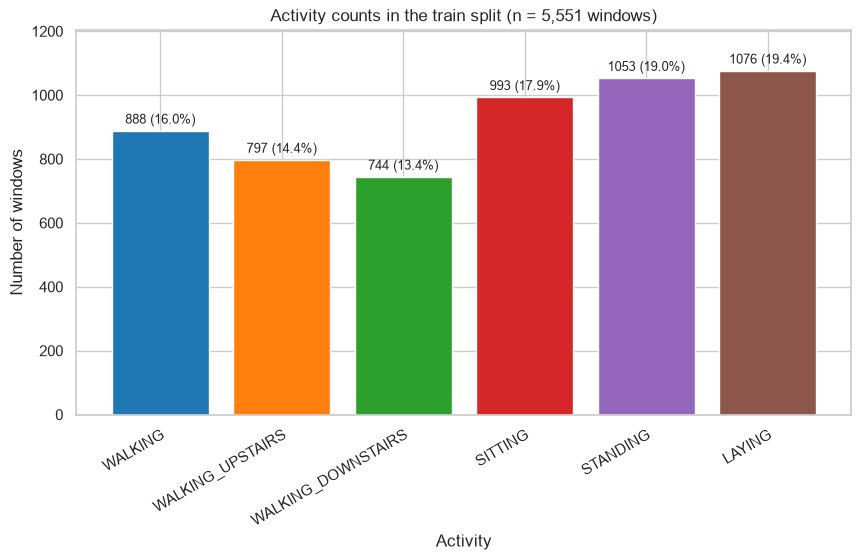

In [8]:
train_counts = pd.Series(y_tr).value_counts().reindex(ACTIVITY_ORDER).rename("n_windows").to_frame()
train_counts["pct"] = (100 * train_counts["n_windows"] / train_counts["n_windows"].sum()).round(1)
train_counts.index.name = "activity"
save_table(train_counts, "phase2_train_activity_counts")
display(train_counts)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(train_counts.index, train_counts["n_windows"],
              color=[ACTIVITY_PALETTE[a] for a in train_counts.index])
ax.bar_label(bars, labels=[f"{n} ({p}%)" for n, p in zip(train_counts["n_windows"], train_counts["pct"])],
             padding=3, fontsize=9)
ax.set_title(f"Activity counts in the train split (n = {len(y_tr):,} windows)")
ax.set_xlabel("Activity")
ax.set_ylabel("Number of windows")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")
ax.set_ylim(0, train_counts["n_windows"].max() * 1.12)
save_fig(fig, "phase2_train_activity_counts")
plt.show()

### 2.2 PCA on train (all components)

In [9]:
from sklearn.decomposition import PCA

t0 = time.perf_counter()
pca = PCA(n_components=None, random_state=RANDOM_STATE).fit(X_tr)
pca_fit_seconds = time.perf_counter() - t0
record_timing("phase2", "pca_fit_all_components", pca_fit_seconds)

evr = pca.explained_variance_ratio_
cum_evr = np.cumsum(evr)
print(f"PCA fitted on train in {pca_fit_seconds:.2f}s: {pca.n_components_} components")

pca_variance = pd.DataFrame({
    "component": np.arange(1, len(evr) + 1),
    "explained_variance_ratio": evr,
    "cumulative_explained_variance": cum_evr,
})
save_table(pca_variance, "phase2_pca_explained_variance", index=False)
display(pca_variance.head(10).round(4))

PCA fitted on train in 0.17s: 561 components
saved results\phase2_pca_explained_variance.csv


,component,explained_variance_ratio,cumulative_explained_variance
0,1,0.5110,0.5110
1,2,0.0626,0.5736
2,3,0.0280,0.6016
3,4,0.0259,0.6275
4,5,0.0197,0.6472
5,6,0.0182,0.6654
6,7,0.0141,0.6795
7,8,0.0118,0.6912
8,9,0.0106,0.7018
9,10,0.0100,0.7119


In [10]:
def elbow_max_distance(y):
    """Elbow of a curve = point with maximum perpendicular distance to the straight line joining its first
    and last points (the kneedle idea). Both axes are min-max normalised to [0, 1] first so the result does
    not depend on their scales. Returns the 1-based index of the elbow and the distance curve."""
    y = np.asarray(y, dtype=float)
    x = np.arange(1, len(y) + 1, dtype=float)
    xn = (x - x[0]) / (x[-1] - x[0])
    yn = (y - y.min()) / (y.max() - y.min())
    p1, p2 = np.array([xn[0], yn[0]]), np.array([xn[-1], yn[-1]])
    dist = np.abs((p2[0] - p1[0]) * (p1[1] - yn) - (p1[0] - xn) * (p2[1] - p1[1])) / np.linalg.norm(p2 - p1)
    return int(x[np.argmax(dist)]), dist


N_PLOT = 50
k_elbow, elbow_dist = elbow_max_distance(evr[:N_PLOT])
k90 = int(np.searchsorted(cum_evr, 0.90) + 1)
k95 = int(np.searchsorted(cum_evr, 0.95) + 1)

print(f"Elbow (max distance to line, first {N_PLOT} components): k = {k_elbow} "
      f"-> cumulative variance {cum_evr[k_elbow - 1]:.1%}")
print(f"Components to reach 90% cumulative variance: {k90}")
print(f"Components to reach 95% cumulative variance: {k95}")

pca_summary = pd.DataFrame({
    "quantity": [f"elbow_k (max-distance, first {N_PLOT} comps)", "k_90pct", "k_95pct", "n_components_total"],
    "value": [k_elbow, k90, k95, pca.n_components_],
    "cumulative_variance_at_k": [cum_evr[k_elbow - 1], cum_evr[k90 - 1], cum_evr[k95 - 1], 1.0],
})
save_table(pca_summary, "phase2_pca_summary", index=False)
display(pca_summary.round(4))

Elbow (max distance to line, first 50 components): k = 3 -> cumulative variance 60.2%
Components to reach 90% cumulative variance: 61
Components to reach 95% cumulative variance: 100
saved results\phase2_pca_summary.csv


,quantity,value,cumulative_variance_at_k
0,"elbow_k (max-distance, first 50 comps)",3,0.6016
1,k_90pct,61,0.9003
2,k_95pct,100,0.9507
3,n_components_total,561,1.0000


In [11]:
# Robustness of the elbow to the cutoff: recompute on the first 30, 50 and 100 components.
# The official k stays the 50-component value (k_elbow above).
elbow_cutoffs = pd.DataFrame([
    {"cutoff_n_components": n, "elbow_k": elbow_max_distance(evr[:n])[0]} for n in (30, 50, 100)
])
elbow_cutoffs["cumulative_variance_at_k"] = cum_evr[elbow_cutoffs["elbow_k"] - 1]
elbow_cutoffs["official"] = elbow_cutoffs["cutoff_n_components"] == N_PLOT

for row in elbow_cutoffs.itertuples():
    tag = "  <- official k" if row.official else ""
    print(f"Elbow on first {row.cutoff_n_components:3d} components: k = {row.elbow_k} "
          f"({row.cumulative_variance_at_k:.1%} cumulative){tag}")
same = elbow_cutoffs["elbow_k"].nunique() == 1
print("k is identical across cutoffs" if same else "k changes with the cutoff -- see table")

save_table(elbow_cutoffs, "phase2_elbow_cutoff_sensitivity", index=False)
display(elbow_cutoffs.round(4))

Elbow on first  30 components: k = 3 (60.2% cumulative)
Elbow on first  50 components: k = 3 (60.2% cumulative)  <- official k
Elbow on first 100 components: k = 3 (60.2% cumulative)
k is identical across cutoffs
saved results\phase2_elbow_cutoff_sensitivity.csv


,cutoff_n_components,elbow_k,cumulative_variance_at_k,official
0,30,3,0.6016,False
1,50,3,0.6016,True
2,100,3,0.6016,False


saved figures\phase2_pca_explained_variance.png

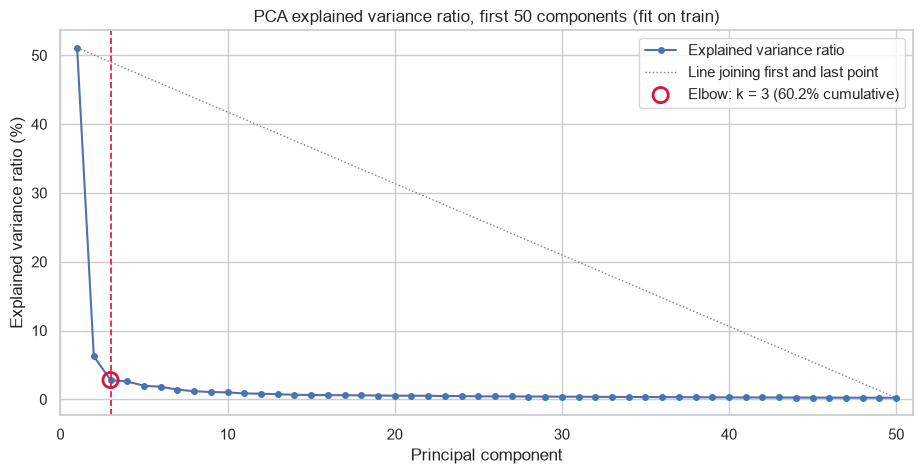

In [12]:
# Explained variance ratio, first 50 components, with the elbow marked
comps = np.arange(1, N_PLOT + 1)
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(comps, 100 * evr[:N_PLOT], marker="o", ms=4, lw=1.5, color="#4C72B0", label="Explained variance ratio")
ax.plot([1, N_PLOT], 100 * evr[[0, N_PLOT - 1]], ls=":", color="gray", lw=1, label="Line joining first and last point")
ax.axvline(k_elbow, color="crimson", ls="--", lw=1.2)
ax.scatter([k_elbow], [100 * evr[k_elbow - 1]], s=120, facecolor="none", edgecolor="crimson", lw=2, zorder=5,
           label=f"Elbow: k = {k_elbow} ({100 * cum_evr[k_elbow - 1]:.1f}% cumulative)")
ax.set_title(f"PCA explained variance ratio, first {N_PLOT} components (fit on train)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio (%)")
ax.set_xlim(0, N_PLOT + 1)
ax.legend()
save_fig(fig, "phase2_pca_explained_variance")
plt.show()

saved figures\phase2_pca_cumulative_variance.png


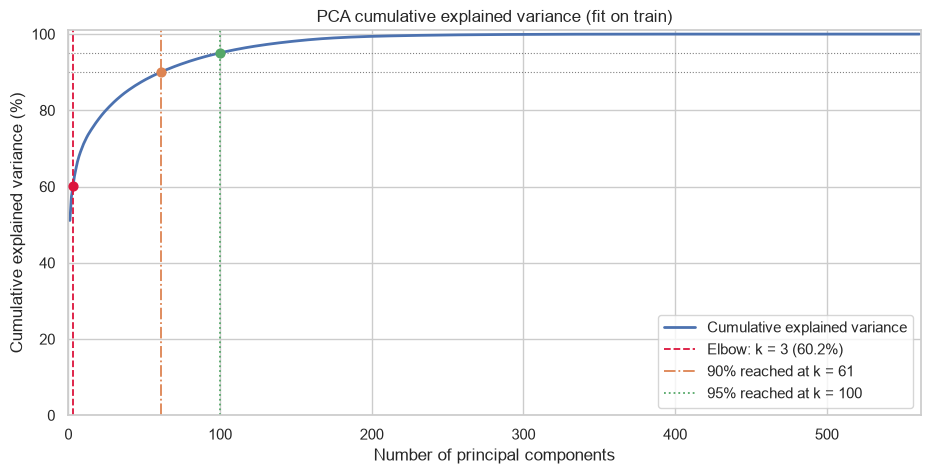

In [13]:
# Cumulative explained variance (all components) with elbow, 90% and 95% marked
all_comps = np.arange(1, len(cum_evr) + 1)
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(all_comps, 100 * cum_evr, lw=2, color="#4C72B0", label="Cumulative explained variance")
markers = [(k_elbow, "crimson", "--", f"Elbow: k = {k_elbow} ({100 * cum_evr[k_elbow - 1]:.1f}%)"),
           (k90, "#DD8452", "-.", f"90% reached at k = {k90}"),
           (k95, "#55A868", ":", f"95% reached at k = {k95}")]
for k, color, ls, label in markers:
    ax.axvline(k, color=color, ls=ls, lw=1.3, label=label)
    ax.scatter([k], [100 * cum_evr[k - 1]], color=color, s=40, zorder=5)
for level in (90, 95):
    ax.axhline(level, color="gray", lw=0.8, ls=":")
ax.set_title("PCA cumulative explained variance (fit on train)")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance (%)")
ax.set_xlim(0, len(cum_evr) + 1)
ax.set_ylim(0, 101)
ax.legend(loc="lower right")
save_fig(fig, "phase2_pca_cumulative_variance")
plt.show()

### 2.3 Train data on PC1 vs PC2

saved figures\phase2_pca_pc1_pc2_scatter.png


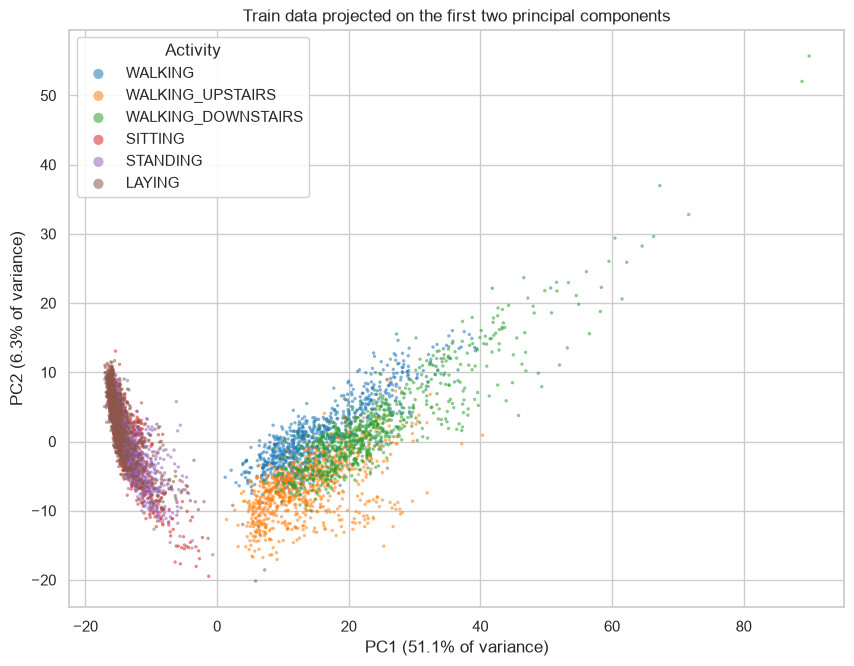

In [14]:
Z_tr = pca.transform(X_tr)[:, :2]

fig, ax = plt.subplots(figsize=(10, 7.5))
for act in ACTIVITY_ORDER:
    m = np.asarray(y_tr) == act
    ax.scatter(Z_tr[m, 0], Z_tr[m, 1], s=6, alpha=0.55, color=ACTIVITY_PALETTE[act], label=act, edgecolors="none")
ax.set_title("Train data projected on the first two principal components")
ax.set_xlabel(f"PC1 ({100 * evr[0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({100 * evr[1]:.1f}% of variance)")
ax.legend(title="Activity", markerscale=3, framealpha=0.9)
save_fig(fig, "phase2_pca_pc1_pc2_scatter")
plt.show()

### 2.4 What PC1, PC2 and PC3 represent: top loadings

Each panel shows the 8 features with the largest absolute loading (coefficient in the principal axis, on the
standardized features) for one component. Bars keep their sign: features on the same side move together
along that component, features on opposite sides move in opposite directions.

saved figures\phase2_pca_top_loadings.png


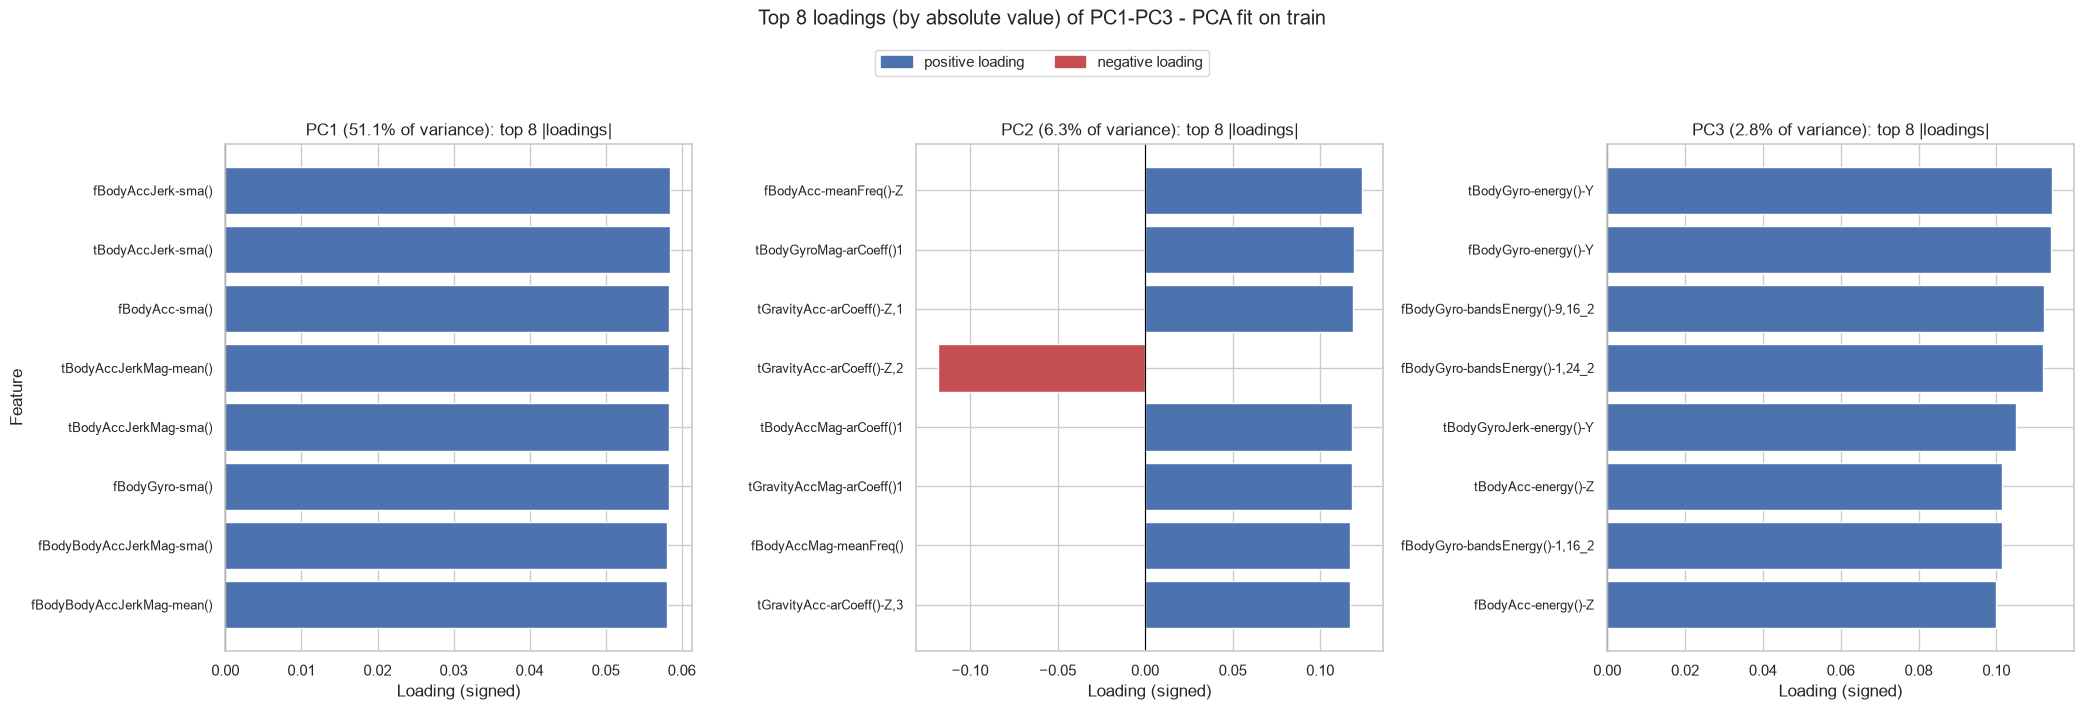

saved results\phase2_pca_top_loadings.csv


component,PC1,PC2,PC3
rank,,,
1,fBodyAccJerk-sma(),fBodyAcc-meanFreq()-Z,tBodyGyro-energy()-Y
2,tBodyAccJerk-sma(),tBodyGyroMag-arCoeff()1,fBodyGyro-energy()-Y
3,fBodyAcc-sma(),"tGravityAcc-arCoeff()-Z,1","fBodyGyro-bandsEnergy()-9,16_2"
4,tBodyAccJerkMag-mean(),"tGravityAcc-arCoeff()-Z,2","fBodyGyro-bandsEnergy()-1,24_2"
5,tBodyAccJerkMag-sma(),tBodyAccMag-arCoeff()1,tBodyGyroJerk-energy()-Y
6,fBodyGyro-sma(),tGravityAccMag-arCoeff()1,tBodyAcc-energy()-Z
7,fBodyBodyAccJerkMag-sma(),fBodyAccMag-meanFreq(),"fBodyGyro-bandsEnergy()-1,16_2"
8,fBodyBodyAccJerkMag-mean(),"tGravityAcc-arCoeff()-Z,3",fBodyAcc-energy()-Z


In [15]:
N_LOAD = 8
loading_rows = []
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for i, ax in enumerate(axes):
    comp = pd.Series(pca.components_[i], index=FEATURE_NAMES)
    top_load = comp.reindex(comp.abs().sort_values(ascending=False).index[:N_LOAD])
    colors = np.where(top_load.values >= 0, "#4C72B0", "#C44E52")
    ax.barh(top_load.index, top_load.values, color=colors)
    ax.invert_yaxis()
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"PC{i + 1} ({100 * evr[i]:.1f}% of variance): top {N_LOAD} |loadings|")
    ax.set_xlabel("Loading (signed)")
    ax.set_ylabel("Feature" if i == 0 else "")
    ax.tick_params(axis="y", labelsize=9)
    loading_rows += [{"component": f"PC{i + 1}", "rank": r + 1, "feature": f, "loading": v}
                     for r, (f, v) in enumerate(top_load.items())]
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color="#4C72B0", label="positive loading"), Patch(color="#C44E52", label="negative loading")],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.04))
fig.suptitle(f"Top {N_LOAD} loadings (by absolute value) of PC1-PC3 - PCA fit on train", y=1.09)
fig.tight_layout()
save_fig(fig, "phase2_pca_top_loadings")
plt.show()

pca_top_loadings = pd.DataFrame(loading_rows)
save_table(pca_top_loadings, "phase2_pca_top_loadings", index=False)
display(pca_top_loadings.pivot(index="rank", columns="component", values="feature"))

**What each component represents** (from the loadings above):

* **PC1 - overall movement intensity:** all top loadings are positive and nearly equal (~0.058) magnitude/area features (`sma`, `Mag-mean`) of body acceleration, jerk and gyroscope, so PC1 is high for walking and low for stationary windows.
* **PC2 - temporal/spectral shape rather than amplitude:** dominated by autoregressive coefficients (`arCoeff`) and mean frequency (`meanFreq`) of body and gravity acceleration, i.e. how the signal oscillates, not how strong it is.
* **PC3 - rotation around the phone's Y axis:** gyroscope Y-axis energy (incl. `bandsEnergy ..._2`, the Y block) plus Z-axis body-acceleration energy.

## Phase 3 - Clustering

The cells below cluster the **train split** without using the activity labels; the labels are only used
afterwards to evaluate (contingency tables and Adjusted Rand Index, ARI).

* **K-Means** on all 561 standardized features for k = 2..10, choosing k by silhouette score
  (`sample_size=3000, random_state=42`), then comparing the silhouette-chosen k with k = 6 (the true number of
  activities).
* **DBSCAN** on the first `k_elbow` PCA components from Phase 2. A k-distance plot (`min_samples=10`) locates
  the knee, eps is swept around it, and the best eps is the one with the highest silhouette among settings
  with at least 2 clusters and at most 10% noise (an unsupervised criterion; ARI is reported, not used to
  choose).

In [16]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

SIL_KW = dict(sample_size=3000, random_state=RANDOM_STATE)
y_tr_arr = np.asarray(y_tr)
Z2_tr = pca.transform(X_tr)[:, :2]          # PC1/PC2 for plotting (PCA fitted on train in Phase 2)


def contingency(clusters, labels, noise_label=-1):
    """Cluster x activity count table; clusters ordered by their dominant activity, noise last."""
    names = np.where(clusters == noise_label, "noise", pd.Series(clusters).map(lambda c: f"cluster {c}"))
    tab = pd.crosstab(pd.Series(names, name="cluster"),
                      pd.Series(pd.Categorical(labels, categories=ACTIVITY_ORDER), name="activity"),
                      dropna=False).reindex(columns=ACTIVITY_ORDER, fill_value=0)
    real = [r for r in tab.index if r != "noise"]
    real.sort(key=lambda r: (ACTIVITY_ORDER.index(tab.loc[r].idxmax()), -tab.loc[r].max()))
    return tab.loc[real + (["noise"] if "noise" in tab.index else [])]


def plot_contingency(tab, title, name):
    """Heatmap of counts; colour = share of each cluster's windows (row %), so purity is visible."""
    row_pct = tab.div(tab.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(tab) + 2.2))
    sns.heatmap(row_pct, annot=tab.values, fmt="d", cmap="Blues", vmin=0, vmax=100, linewidths=0.5,
                cbar_kws={"label": "% of cluster's windows"}, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("True activity")
    ax.set_ylabel("Cluster (size)")
    ax.set_yticklabels([f"{r} ({n})" for r, n in zip(tab.index, tab.sum(axis=1))], rotation=0)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")
    save_fig(fig, name)
    plt.show()


def plot_clusters_pc12(clusters, title, name, noise_label=-1):
    """Train data on PC1/PC2 coloured by cluster; noise (if any) in grey underneath."""
    ids = [c for c in np.unique(clusters) if c != noise_label]
    colors = dict(zip(ids, sns.color_palette("husl", len(ids))))
    fig, ax = plt.subplots(figsize=(10, 7.5))
    m = clusters == noise_label
    if m.any():
        ax.scatter(Z2_tr[m, 0], Z2_tr[m, 1], s=6, color="lightgrey", alpha=0.7, edgecolors="none",
                   label=f"noise ({m.sum()})")
    for c in ids:
        m = clusters == c
        ax.scatter(Z2_tr[m, 0], Z2_tr[m, 1], s=6, alpha=0.6, color=colors[c], edgecolors="none",
                   label=f"cluster {c} ({m.sum()})")
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({100 * evr[0]:.1f}% of variance)")
    ax.set_ylabel(f"PC2 ({100 * evr[1]:.1f}% of variance)")
    ax.legend(title="Cluster (size)", markerscale=3, framealpha=0.9, fontsize=8)
    save_fig(fig, name)
    plt.show()

### 3.1 K-Means on all 561 standardized features: choosing k by silhouette

In [17]:
K_RANGE = range(2, 11)
kmeans_labels, rows = {}, []
for k in K_RANGE:
    t0 = time.perf_counter()
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_tr)
    record_timing("phase3", f"kmeans_k{k}", time.perf_counter() - t0)
    kmeans_labels[k] = km.labels_
    rows.append({"k": k, "silhouette": silhouette_score(X_tr, km.labels_, **SIL_KW),
                 # float32 inertia wobbles in the 7th significant digit between runs; round it away
                 "inertia": round(float(km.inertia_)),
                 "ari_vs_activity": adjusted_rand_score(y_tr_arr, km.labels_)})
kmeans_sweep = pd.DataFrame(rows)
k_best = int(kmeans_sweep.loc[kmeans_sweep["silhouette"].idxmax(), "k"])

save_table(kmeans_sweep, "phase3_kmeans_silhouette", index=False)
display(kmeans_sweep.round(4))
print(f"Best k by silhouette: k = {k_best} (silhouette = {kmeans_sweep['silhouette'].max():.4f})")
print("(ARI is shown for reference only; k is chosen by silhouette alone.)")

saved results\phase3_kmeans_silhouette.csv


,k,silhouette,inertia,ari_vs_activity
0,2,0.4065,1741156,0.3292
1,3,0.3502,1556465,0.3252
2,4,0.1568,1481624,0.2904
3,5,0.1192,1409342,0.2943
4,6,0.1056,1364658,0.4310
5,7,0.1084,1332076,0.3525
6,8,0.1104,1296042,0.4250
7,9,0.0807,1271783,0.4332
8,10,0.1051,1244471,0.3736


Best k by silhouette: k = 2 (silhouette = 0.4065)
(ARI is shown for reference only; k is chosen by silhouette alone.)


saved figures\phase3_kmeans_silhouette_inertia_vs_k.png


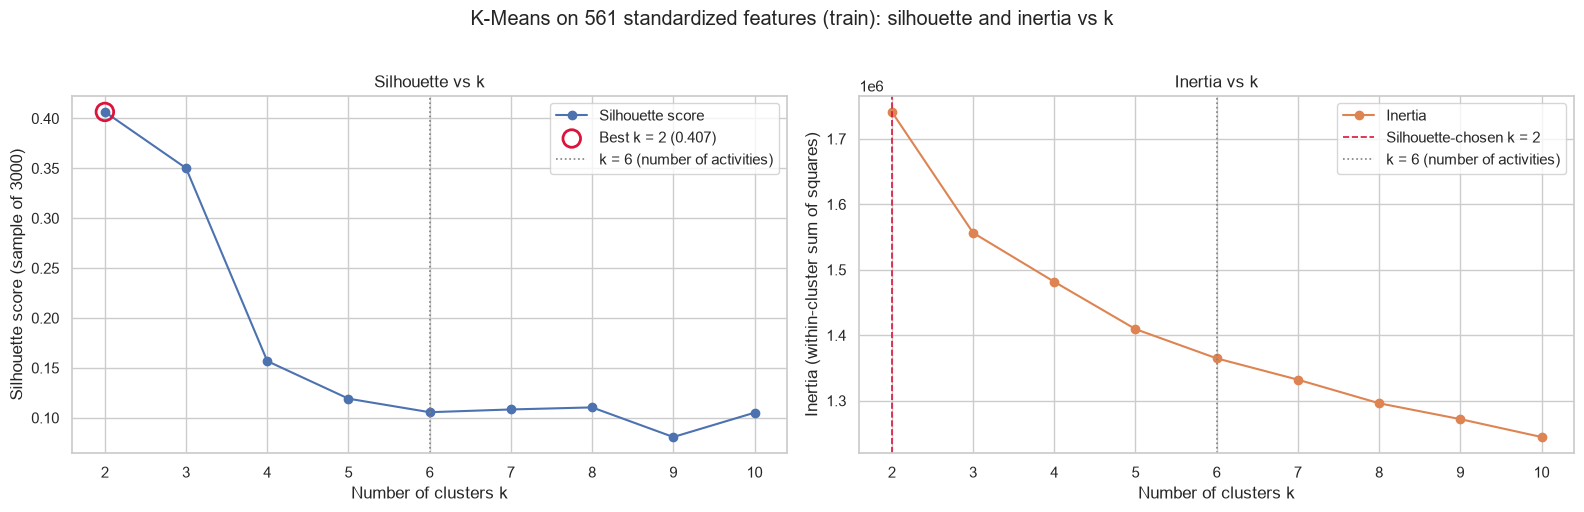

In [18]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5))
ax.plot(kmeans_sweep["k"], kmeans_sweep["silhouette"], marker="o", color="#4C72B0", label="Silhouette score")
best = kmeans_sweep.set_index("k").loc[k_best, "silhouette"]
ax.scatter([k_best], [best], s=160, facecolor="none", edgecolor="crimson", lw=2, zorder=5,
           label=f"Best k = {k_best} ({best:.3f})")
ax.axvline(6, color="gray", ls=":", lw=1.2, label="k = 6 (number of activities)")
ax.set_title("Silhouette vs k")
ax.set_xlabel("Number of clusters k")
ax.set_ylabel("Silhouette score (sample of 3000)")
ax.set_xticks(list(K_RANGE))
ax.legend()

ax2.plot(kmeans_sweep["k"], kmeans_sweep["inertia"], marker="o", color="#DD8452", label="Inertia")
ax2.axvline(k_best, color="crimson", ls="--", lw=1.2, label=f"Silhouette-chosen k = {k_best}")
ax2.axvline(6, color="gray", ls=":", lw=1.2, label="k = 6 (number of activities)")
ax2.set_title("Inertia vs k")
ax2.set_xlabel("Number of clusters k")
ax2.set_ylabel("Inertia (within-cluster sum of squares)")
ax2.set_xticks(list(K_RANGE))
ax2.legend()
fig.suptitle("K-Means on 561 standardized features (train): silhouette and inertia vs k", y=1.02)
fig.tight_layout()
save_fig(fig, "phase3_kmeans_silhouette_inertia_vs_k")
plt.show()

### 3.2 K-Means with the silhouette-chosen k

K-Means k = 2: ARI vs true activity = 0.3292


saved figures\phase3_kmeans_best_pc12.png


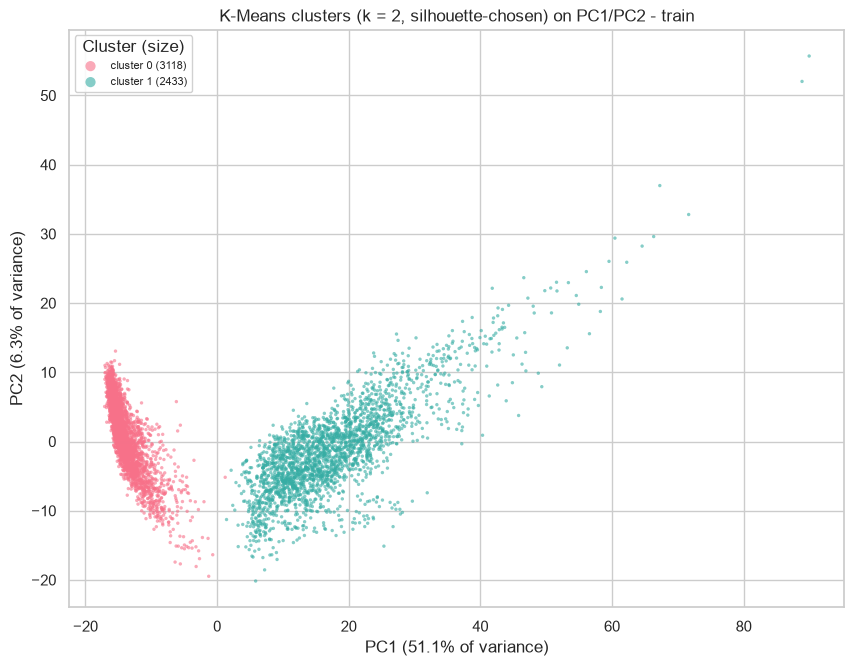

saved results\phase3_kmeans_k2_contingency.csv

saved figures\phase3_kmeans_k2_contingency.png


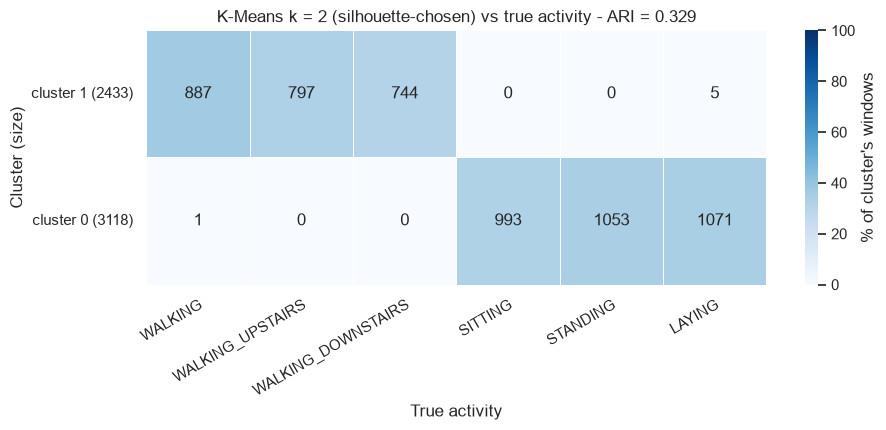

In [19]:
lab_best = kmeans_labels[k_best]
ari_best = adjusted_rand_score(y_tr_arr, lab_best)
print(f"K-Means k = {k_best}: ARI vs true activity = {ari_best:.4f}")

plot_clusters_pc12(lab_best, f"K-Means clusters (k = {k_best}, silhouette-chosen) on PC1/PC2 - train",
                   "phase3_kmeans_best_pc12")
tab_best = contingency(lab_best, y_tr_arr)
save_table(tab_best, f"phase3_kmeans_k{k_best}_contingency")
plot_contingency(tab_best, f"K-Means k = {k_best} (silhouette-chosen) vs true activity - ARI = {ari_best:.3f}",
                 f"phase3_kmeans_k{k_best}_contingency")

### 3.3 K-Means with k = 6 (the true number of activities)

K-Means k = 6: ARI vs true activity = 0.4310
saved results\phase3_kmeans_k6_contingency.csv


saved figures\phase3_kmeans_k6_contingency.png


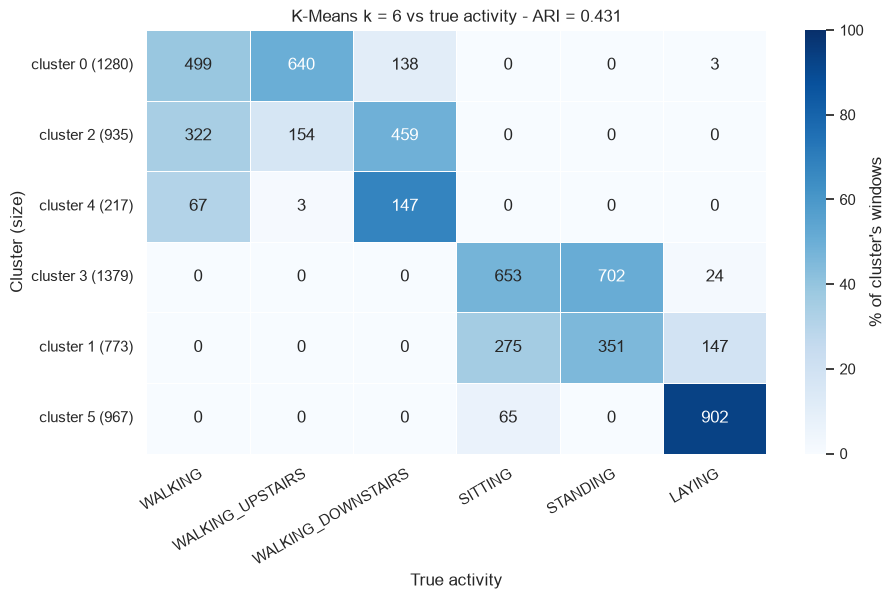

saved results\phase3_kmeans_best_vs_k6.csv


,choice,silhouette,ari_vs_activity
k,,,
2,silhouette-chosen,0.4065,0.3292
6,natural (6 activities),0.1056,0.4310


In [20]:
lab_k6 = kmeans_labels[6]
ari_k6 = adjusted_rand_score(y_tr_arr, lab_k6)
print(f"K-Means k = 6: ARI vs true activity = {ari_k6:.4f}")

tab_k6 = contingency(lab_k6, y_tr_arr)
save_table(tab_k6, "phase3_kmeans_k6_contingency")
plot_contingency(tab_k6, f"K-Means k = 6 vs true activity - ARI = {ari_k6:.3f}", "phase3_kmeans_k6_contingency")

kmeans_compare = kmeans_sweep.set_index("k").loc[[k_best, 6], ["silhouette", "ari_vs_activity"]]
kmeans_compare.insert(0, "choice", ["silhouette-chosen" if k_best != 6 else "silhouette-chosen = natural",
                                     "natural (6 activities)"][:len(kmeans_compare)])
save_table(kmeans_compare, "phase3_kmeans_best_vs_k6")
display(kmeans_compare.round(4))

### 3.4 DBSCAN on the top `k_elbow` PCA components: k-distance plot

DBSCAN space: first 3 PCA components -> (5551, 3)
k-distance knee: eps = 4.111 (at sorted point 5419 of 5551)
saved figures\phase3_dbscan_k_distance.png


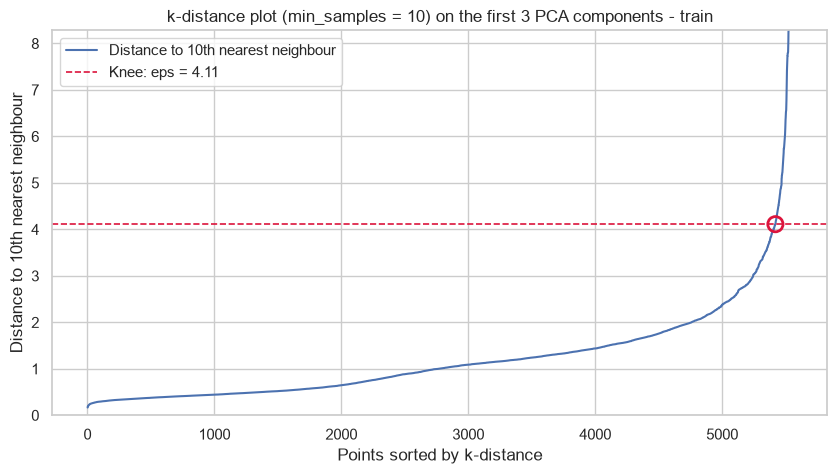

In [21]:
MIN_SAMPLES = 10
Zk_tr = pca.transform(X_tr)[:, :k_elbow]
print(f"DBSCAN space: first {k_elbow} PCA components -> {Zk_tr.shape}")

# Distance to the min_samples-th nearest neighbour. kneighbors on the fitted data returns the point itself
# as its first neighbour, which matches DBSCAN's min_samples (that count includes the point itself).
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Zk_tr)
kdist = np.sort(nn.kneighbors(Zk_tr)[0][:, -1])
knee_idx, _ = elbow_max_distance(kdist)          # same max-distance-to-line method as Phase 2
eps_knee = float(kdist[knee_idx - 1])
print(f"k-distance knee: eps = {eps_knee:.3f} (at sorted point {knee_idx} of {len(kdist)})")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(np.arange(1, len(kdist) + 1), kdist, color="#4C72B0", lw=1.5,
        label=f"Distance to {MIN_SAMPLES}th nearest neighbour")
ax.axhline(eps_knee, color="crimson", ls="--", lw=1.2, label=f"Knee: eps = {eps_knee:.2f}")
ax.scatter([knee_idx], [eps_knee], s=120, facecolor="none", edgecolor="crimson", lw=2, zorder=5)
ax.set_title(f"k-distance plot (min_samples = {MIN_SAMPLES}) on the first {k_elbow} PCA components - train")
ax.set_xlabel("Points sorted by k-distance")
ax.set_ylabel(f"Distance to {MIN_SAMPLES}th nearest neighbour")
ax.set_ylim(0, np.percentile(kdist, 99.5))   # cap at the 99.5th percentile so outliers don't squash the knee
ax.legend()
save_fig(fig, "phase3_dbscan_k_distance")
plt.show()

### 3.5 DBSCAN eps sweep around the knee

Silhouette is computed in the same PCA space DBSCAN clusters in, on non-noise points only, and only when there
are at least 2 clusters. ARI treats noise as one extra group (all points); `ari_non_noise` is also reported.

In [22]:
eps_grid = np.round(np.linspace(0.5 * eps_knee, 2.0 * eps_knee, 31), 4)
rows, dbscan_labels = [], {}
for eps in eps_grid:
    t0 = time.perf_counter()
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Zk_tr)
    record_timing("phase3", f"dbscan_eps{eps}", time.perf_counter() - t0)
    dbscan_labels[eps] = lab
    core = lab != -1
    n_clusters = len(set(lab[core]))
    sil = np.nan
    if n_clusters >= 2:
        sil = silhouette_score(Zk_tr[core], lab[core], **SIL_KW)
    rows.append({"eps": eps, "n_clusters": n_clusters, "noise_pct": 100 * (~core).mean(), "silhouette": sil,
                 "ari": adjusted_rand_score(y_tr_arr, lab),
                 "ari_non_noise": adjusted_rand_score(y_tr_arr[core], lab[core]) if core.any() else np.nan})
dbscan_sweep = pd.DataFrame(rows)

MAX_NOISE_PCT = 10.0
eligible = dbscan_sweep[(dbscan_sweep["n_clusters"] >= 2) & (dbscan_sweep["noise_pct"] <= MAX_NOISE_PCT)
                        & dbscan_sweep["silhouette"].notna()]
assert len(eligible), "no eps gives >= 2 clusters with <= 10% noise; widen the eps grid"
best_row = eligible.loc[eligible["silhouette"].idxmax()]
eps_best = float(best_row["eps"])
dbscan_sweep["selected"] = dbscan_sweep["eps"] == eps_best

save_table(dbscan_sweep, "phase3_dbscan_eps_sweep", index=False)
display(dbscan_sweep.round(4))
print(f"Best eps (max silhouette, >= 2 clusters, noise <= {MAX_NOISE_PCT:.0f}%): eps = {eps_best:.3f} -> "
      f"{int(best_row['n_clusters'])} clusters, {best_row['noise_pct']:.1f}% noise, "
      f"silhouette {best_row['silhouette']:.4f}, ARI {best_row['ari']:.4f}")

saved results\phase3_dbscan_eps_sweep.csv


,eps,n_clusters,noise_pct,silhouette,ari,ari_non_noise,selected
0,2.0554,5,8.1247,0.5373,0.3145,0.3240,False
1,2.2609,5,6.4673,0.6034,0.3195,0.3265,False
2,2.4665,6,5.1883,0.5738,0.3214,0.3268,False
3,2.6720,5,4.0533,0.4302,0.3249,0.3280,False
4,2.8775,5,3.1886,0.4991,0.3259,0.3282,False
5,3.0831,3,2.8643,0.6146,0.3271,0.3290,True
6,3.2886,3,2.5221,0.6137,0.3274,0.3290,False
7,3.4942,4,2.1798,0.6038,0.3274,0.3289,False
8,3.6997,4,1.6754,0.5689,0.3274,0.3290,False
9,3.9052,3,1.4772,0.6003,0.3278,0.3291,False


Best eps (max silhouette, >= 2 clusters, noise <= 10%): eps = 3.083 -> 3 clusters, 2.9% noise, silhouette 0.6146, ARI 0.3271


saved figures\phase3_dbscan_eps_sweep.png


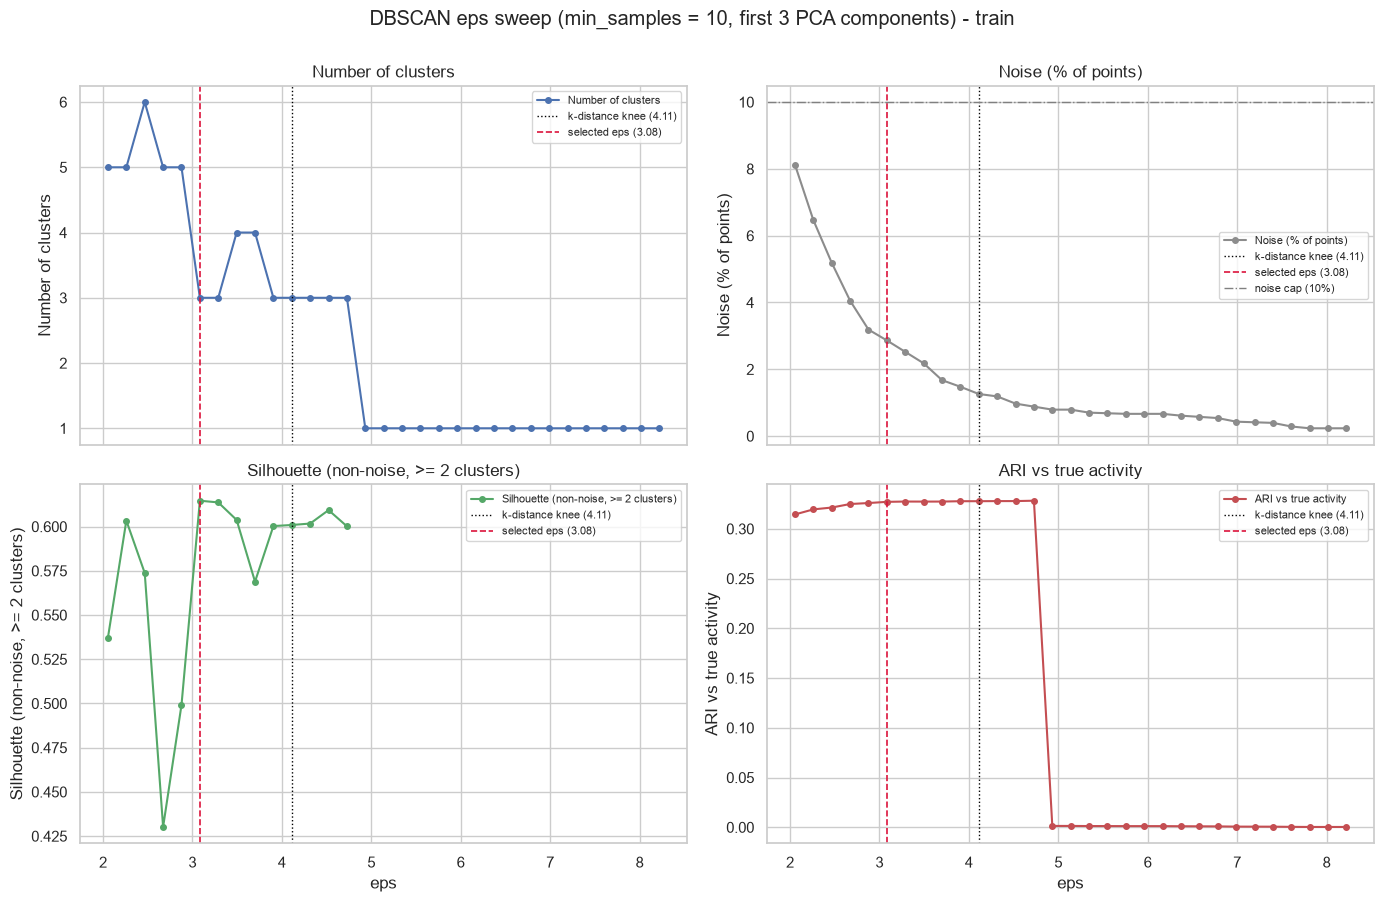

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
panels = [("n_clusters", "Number of clusters", "#4C72B0"), ("noise_pct", "Noise (% of points)", "#8C8C8C"),
          ("silhouette", "Silhouette (non-noise, >= 2 clusters)", "#55A868"), ("ari", "ARI vs true activity", "#C44E52")]
for ax, (col, label, color) in zip(axes.ravel(), panels):
    ax.plot(dbscan_sweep["eps"], dbscan_sweep[col], marker="o", ms=4, color=color, label=label)
    ax.axvline(eps_knee, color="black", ls=":", lw=1, label=f"k-distance knee ({eps_knee:.2f})")
    ax.axvline(eps_best, color="crimson", ls="--", lw=1.2, label=f"selected eps ({eps_best:.2f})")
    if col == "noise_pct":
        ax.axhline(MAX_NOISE_PCT, color="gray", ls="-.", lw=1, label=f"noise cap ({MAX_NOISE_PCT:.0f}%)")
    ax.set_title(label)
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("eps")
fig.suptitle(f"DBSCAN eps sweep (min_samples = {MIN_SAMPLES}, first {k_elbow} PCA components) - train", y=1.0)
fig.tight_layout()
save_fig(fig, "phase3_dbscan_eps_sweep")
plt.show()

### 3.6 Best DBSCAN setting

saved figures\phase3_dbscan_best_pc12.png


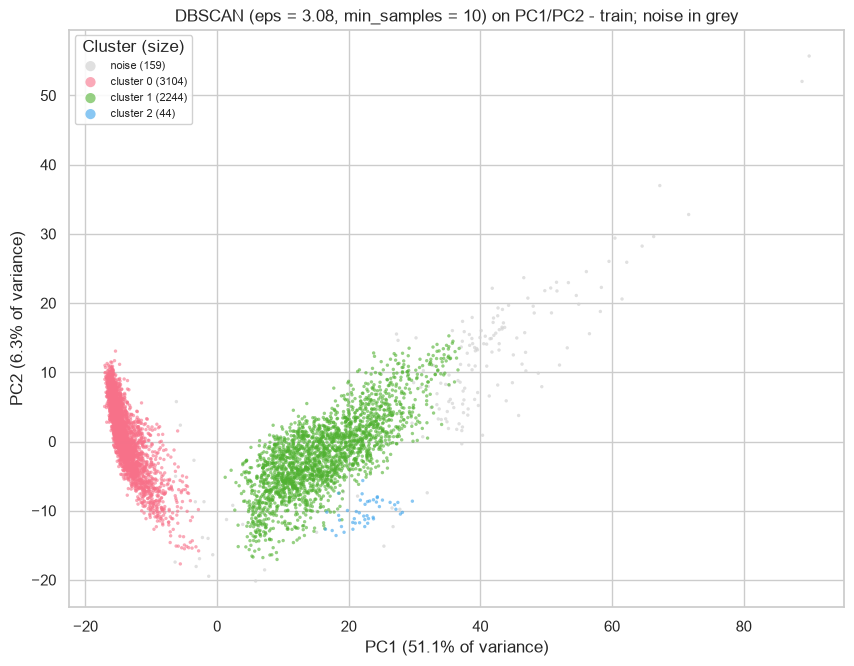

saved results\phase3_dbscan_best_contingency.csv


saved figures\phase3_dbscan_best_contingency.png


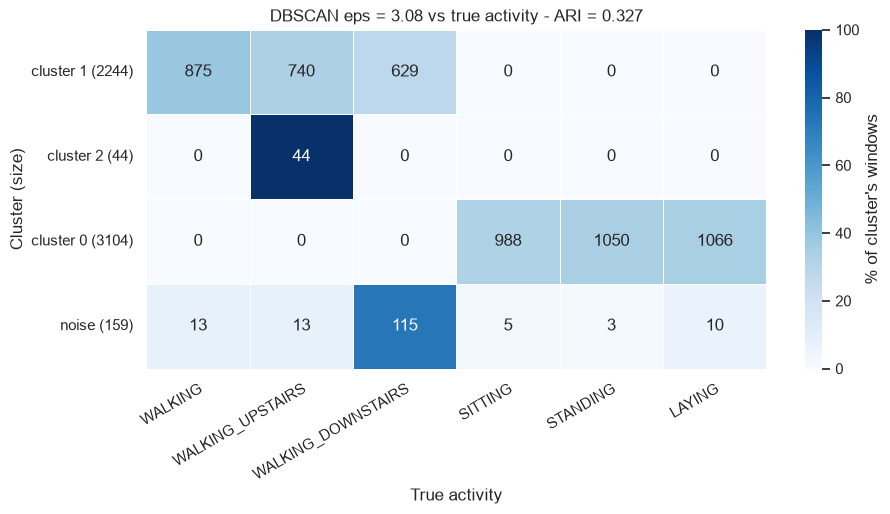

In [24]:
lab_db = dbscan_labels[eps_best]
ari_db = adjusted_rand_score(y_tr_arr, lab_db)
plot_clusters_pc12(lab_db, f"DBSCAN (eps = {eps_best:.2f}, min_samples = {MIN_SAMPLES}) on PC1/PC2 - train; noise in grey",
                   "phase3_dbscan_best_pc12")
tab_db = contingency(lab_db, y_tr_arr)
save_table(tab_db, "phase3_dbscan_best_contingency")
plot_contingency(tab_db, f"DBSCAN eps = {eps_best:.2f} vs true activity - ARI = {ari_db:.3f}",
                 "phase3_dbscan_best_contingency")

In [25]:
# Summary of the three clusterings compared in this phase
phase3_summary = pd.DataFrame([
    {"method": f"K-Means k={k_best} (silhouette-chosen)", "space": "561 standardized features",
     "n_clusters": k_best, "noise_pct": 0.0,
     "silhouette": kmeans_sweep.set_index("k").loc[k_best, "silhouette"], "ari": ari_best},
    {"method": "K-Means k=6 (natural)", "space": "561 standardized features", "n_clusters": 6, "noise_pct": 0.0,
     "silhouette": kmeans_sweep.set_index("k").loc[6, "silhouette"], "ari": ari_k6},
    {"method": f"DBSCAN eps={eps_best:.2f}, min_samples={MIN_SAMPLES}", "space": f"first {k_elbow} PCA components",
     "n_clusters": int(best_row["n_clusters"]), "noise_pct": best_row["noise_pct"],
     "silhouette": best_row["silhouette"], "ari": ari_db},
])
save_table(phase3_summary, "phase3_summary", index=False)
display(phase3_summary.round(4))
print("Note: silhouettes are computed in each method's own space, so compare them within a method, not across.")

saved results\phase3_summary.csv


,method,space,n_clusters,noise_pct,silhouette,ari
0,K-Means k=2 (silhouette-chosen),561 standardized features,2,0.0000,0.4065,0.3292
1,K-Means k=6 (natural),561 standardized features,6,0.0000,0.1056,0.4310
2,"DBSCAN eps=3.08, min_samples=10",first 3 PCA components,3,2.8643,0.6146,0.3271


Note: silhouettes are computed in each method's own space, so compare them within a method, not across.


## Phase 4 - Two ways to shrink features

The cells below compare two ways of reducing the 561 features, using the **train split only** (dev and test
are not touched):

* **TRANSFORM** - PCA, reusing the Phase 2 fit on train. Train is projected onto the first `k_elbow`, `k90` and
  `k95` components (elbow, 90% and 95% cumulative variance).
* **SELECT** - keep a subset of the original, interpretable features. A `RandomForestClassifier`
  (`n_estimators=300, random_state=42, n_jobs=-1`) is fitted on train and the 561 features are ranked by
  impurity importance. The top 20 are summarised by domain, signal and axis, and cumulative importance shows
  how many features carry 50/80/90% of the total.

Labels are used only to fit the random forest on train. Caveat: impurity importance is shared among correlated
features, and Phase 2 showed many near-duplicates, so one useful signal can rank lower than it deserves when
several copies split its credit.

### 4.1 TRANSFORM: PCA (Phase 2 fit on train)

In [26]:
assert pca.n_features_in_ == X_tr.shape[1]      # same PCA object fitted on train in Phase 2
Z_all_tr = pca.transform(X_tr)

PCA_SETS = {"pca_elbow": k_elbow, "pca_90": k90, "pca_95": k95}
pca_reduced_tr = {name: Z_all_tr[:, :k] for name, k in PCA_SETS.items()}

pca_reduced_summary = pd.DataFrame([
    {"set": name, "n_components": k, "train_shape": str(pca_reduced_tr[name].shape),
     "retained_variance": cum_evr[k - 1], "reduction_vs_561": f"{100 * (1 - k / X_tr.shape[1]):.1f}%"}
    for name, k in PCA_SETS.items()
])
save_table(pca_reduced_summary, "phase4_pca_reduced_sets", index=False)
display(pca_reduced_summary.round(4))

saved results\phase4_pca_reduced_sets.csv

,set,n_components,train_shape,retained_variance,reduction_vs_561
0,pca_elbow,3,"(5551, 3)",0.6016,99.5%
1,pca_90,61,"(5551, 61)",0.9003,89.1%
2,pca_95,100,"(5551, 100)",0.9507,82.2%


### 4.2 SELECT: random-forest impurity importance

In [27]:
from sklearn.ensemble import RandomForestClassifier
import re

t0 = time.perf_counter()
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(X_tr, y_tr_arr)
rf_fit_seconds = time.perf_counter() - t0
record_timing("phase4", "random_forest_fit", rf_fit_seconds)
print(f"Random forest (300 trees) fitted on train in {rf_fit_seconds:.1f}s")


def feature_groups(name):
    """(domain, signal, axis) for a feature name.

    domain: time / frequency / angle.  signal: body acc / gravity acc / gyroscope / angle.
    axis: X / Y / Z, an axis pair for correlation features (e.g. 'X,Y'), or 'none' (magnitude features).
    features.txt does not name the axis of bandsEnergy features: each signal lists the same 14 bands three
    times, in X, Y, Z order (the convention used by all other features). Phase 1 made those names unique with
    suffixes, so no suffix = X, '_2' = Y, '_3' = Z.
    """
    if name.startswith("angle("):
        m = re.match(r"angle\(([XYZ]),", name)
        return "angle", "angle", (m.group(1) if m else "none")
    domain = "time" if name[0] == "t" else "frequency"
    sig = name.split("-", 1)[0]
    signal = "gyroscope" if "Gyro" in sig else "gravity acc" if "Gravity" in sig else "body acc"
    if "bandsEnergy" in name:
        axis = {"_2": "Y", "_3": "Z"}.get(name[-2:], "X")
    else:
        m = re.search(r"-([XYZ])(?:,([XYZ]))?(?:,\d)?$", name)
        axis = (m.group(1) + ("," + m.group(2) if m.group(2) else "")) if m else "none"
    return domain, signal, axis


importance = (pd.DataFrame({"feature": FEATURE_NAMES, "importance": rf.feature_importances_})
              .sort_values("importance", ascending=False, ignore_index=True))
importance.insert(0, "rank", np.arange(1, len(importance) + 1))
importance["cumulative_importance"] = importance["importance"].cumsum()
importance[["domain", "signal", "axis"]] = pd.DataFrame(importance["feature"].map(feature_groups).tolist())

save_table(importance, "phase4_rf_feature_importance_ranking", index=False)
display(importance.head(20).round(4))

Random forest (300 trees) fitted on train in 1.6s
saved results\phase4_rf_feature_importance_ranking.csv


,rank,feature,importance,cumulative_importance,domain,signal,axis
0,1,tGravityAcc-mean()-X,0.0343,0.0343,time,gravity acc,X
1,2,tGravityAcc-min()-X,0.0311,0.0654,time,gravity acc,X
2,3,"angle(X,gravityMean)",0.0287,0.0942,angle,angle,X
3,4,tGravityAcc-energy()-X,0.0256,0.1198,time,gravity acc,X
4,5,tGravityAcc-mean()-Y,0.0252,0.1449,time,gravity acc,Y
5,6,tGravityAcc-min()-Y,0.0218,0.1667,time,gravity acc,Y
6,7,tGravityAcc-max()-X,0.0215,0.1883,time,gravity acc,X
7,8,tGravityAcc-max()-Y,0.0206,0.2088,time,gravity acc,Y
8,9,"angle(Y,gravityMean)",0.0196,0.2284,angle,angle,Y
9,10,tGravityAcc-energy()-Y,0.0146,0.2430,time,gravity acc,Y


saved figures\phase4_rf_top20_importance.png


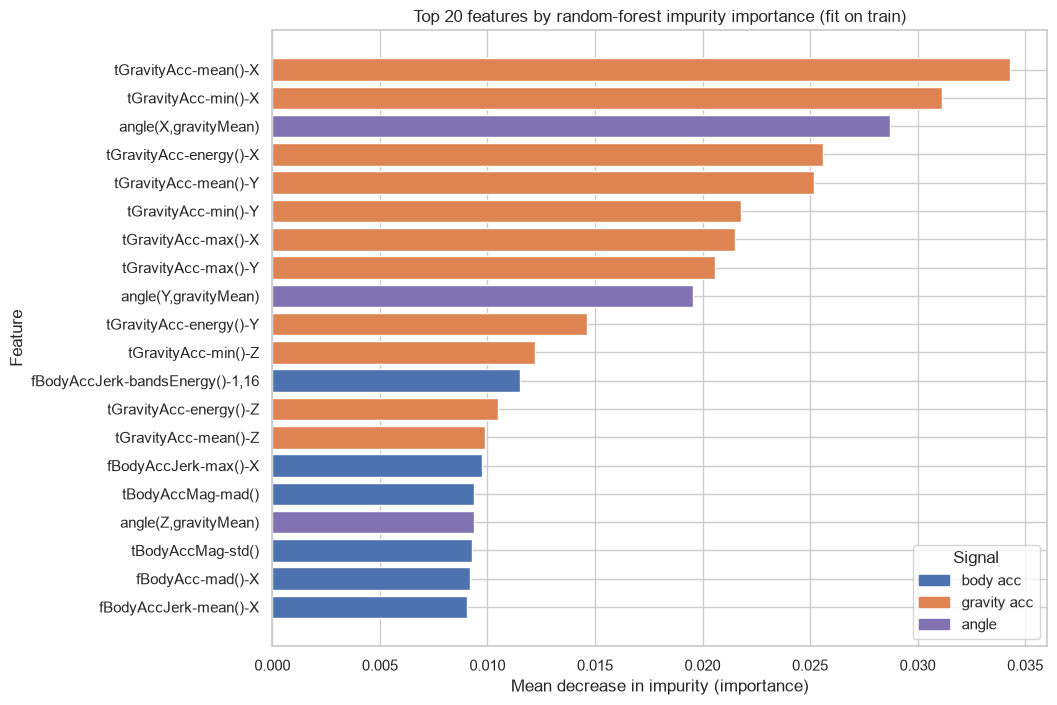

In [28]:
TOP_N = 20
top = importance.head(TOP_N)
signal_colors = {"body acc": "#4C72B0", "gravity acc": "#DD8452", "gyroscope": "#55A868", "angle": "#8172B2"}

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top["feature"], top["importance"], color=top["signal"].map(signal_colors))
ax.invert_yaxis()
ax.set_title(f"Top {TOP_N} features by random-forest impurity importance (fit on train)")
ax.set_xlabel("Mean decrease in impurity (importance)")
ax.set_ylabel("Feature")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=s) for s, c in signal_colors.items() if s in set(top["signal"])],
          title="Signal", loc="lower right")
save_fig(fig, "phase4_rf_top20_importance")
plt.show()

In [29]:
# Summarise the top 20 along three separate dimensions (each breakdown sums to 20).
# Every group that exists among the 561 features is listed, so groups absent from the top 20 show as 0.
group_rows = []
for dim in ["domain", "signal", "axis"]:
    counts = top[dim].value_counts().reindex(importance[dim].unique(), fill_value=0)
    counts = counts.sort_values(ascending=False, kind="stable")
    print(f"Top {TOP_N} by {dim}: " + ", ".join(f"{k} = {v}" for k, v in counts.items()))
    group_rows += [{"dimension": dim, "group": k, "count": int(v),
                    "share_of_top20_importance": top.loc[top[dim] == k, "importance"].sum() / top["importance"].sum()}
                   for k, v in counts.items()]
top20_groups = pd.DataFrame(group_rows)
save_table(top20_groups, "phase4_top20_group_counts", index=False)
display(top20_groups.round(3))

Top 20 by domain: time = 13, frequency = 4, angle = 3
Top 20 by signal: gravity acc = 11, body acc = 6, angle = 3, gyroscope = 0
Top 20 by axis: X = 9, Y = 5, Z = 4, none = 2, X,Y = 0, Y,Z = 0, X,Z = 0
saved results\phase4_top20_group_counts.csv


,dimension,group,count,share_of_top20_importance
0,domain,time,13,0.717
1,domain,frequency,4,0.115
2,domain,angle,3,0.168
3,signal,gravity acc,11,0.662
4,signal,body acc,6,0.170
5,signal,angle,3,0.168
6,signal,gyroscope,0,0.000
7,axis,X,9,0.527
8,axis,Y,5,0.297
9,axis,Z,4,0.122


### 4.3 Cumulative importance vs number of features

50% of total importance reached with 43 features (7.7% of 561)
80% of total importance reached with 137 features (24.4% of 561)
90% of total importance reached with 232 features (41.4% of 561)
saved results\phase4_importance_thresholds.csv
saved figures\phase4_rf_cumulative_importance.png


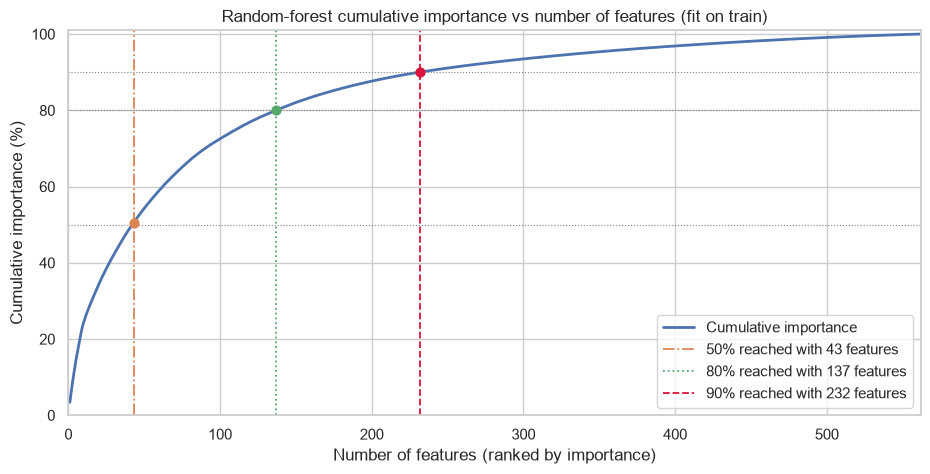

In [30]:
thresholds = [0.50, 0.80, 0.90]
n_for = {t: int(np.searchsorted(importance["cumulative_importance"].to_numpy(), t) + 1) for t in thresholds}
for t in thresholds:
    print(f"{int(t * 100)}% of total importance reached with {n_for[t]} features "
          f"({100 * n_for[t] / len(importance):.1f}% of 561)")

importance_thresholds = pd.DataFrame({"importance_threshold": thresholds,
                                      "n_features": [n_for[t] for t in thresholds],
                                      "pct_of_561": [round(100 * n_for[t] / len(importance), 1) for t in thresholds]})
save_table(importance_thresholds, "phase4_importance_thresholds", index=False)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(importance["rank"], 100 * importance["cumulative_importance"], lw=2, color="#4C72B0",
        label="Cumulative importance")
for t, color, ls in zip(thresholds, ["#DD8452", "#55A868", "crimson"], ["-.", ":", "--"]):
    ax.axvline(n_for[t], color=color, ls=ls, lw=1.3, label=f"{int(t * 100)}% reached with {n_for[t]} features")
    ax.axhline(100 * t, color="gray", lw=0.8, ls=":")
    ax.scatter([n_for[t]], [100 * importance["cumulative_importance"].iloc[n_for[t] - 1]], color=color, s=40, zorder=5)
ax.set_title("Random-forest cumulative importance vs number of features (fit on train)")
ax.set_xlabel("Number of features (ranked by importance)")
ax.set_ylabel("Cumulative importance (%)")
ax.set_xlim(0, len(importance) + 1)
ax.set_ylim(0, 101)
ax.legend(loc="lower right")
save_fig(fig, "phase4_rf_cumulative_importance")
plt.show()